In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import sys
sys.path.append('../')
from src.ConstitutiveModel import DebyeModel
from src.PlaneWave import PlaneWave
from src.LayeredColumn import LayeredColumn
from src.ConstitutiveModel import MixingModel

%reload_ext autoreload
%autoreload 2

# Layered model

In [ ]:
# add LayeredColumn
# define constitutive models
omega_run  = 2 * np.pi * np.logspace(6, 9, 1000)  # frequency range from 1 Mhz to 1 GHz
omega_plot = 2 * np.pi * np.array([1e6, 1e7, 1e8, 1e9]) # for plotting
f      = omega_run / (2 * np.pi)
f_plot = omega_plot / (2 * np.pi)

# ------------- clean ice ---------------
ice_eps_infty = 3.15
ice_eps_s = 75
ice_delta_eps = ice_eps_s - ice_eps_infty
ice_sigma_s = 1e-9
ice_fr = 5e3 
ice_omega_r = 2 * np.pi * ice_fr
ice_tau = 1 / ice_omega_r

clean_ice_model = DebyeModel(
    eps_infty=ice_eps_infty,
    delta_eps=ice_delta_eps,
    sigma_s=ice_sigma_s,
    tau_0=ice_tau)
clean_ice_fn = lambda omega: clean_ice_model.debye(omega)[0]

# ------------- debris ladden ice ---------------
# These are sensitivity-test values, not a calibrated rock model.
rock_eps_infty = 6.0
rock_eps_s = 10.0
rock_fr = 1e6       # relaxation frequency [Hz]
rock_sigma = 1e-5  # DC conductivity [S/m]
rock_tau = 1 / (2 * np.pi * rock_fr)

rock_model = DebyeModel(
    eps_infty=rock_eps_infty,
    delta_eps=rock_eps_s - rock_eps_infty,
    sigma_s=rock_sigma,
    tau_0=rock_tau,
)

rock_fn = lambda omega: rock_model.debye(omega)[0]

# mixture model
mixing_model = MixingModel(
    inclusion_model=rock_fn,
    host_model=clean_ice_fn,
    fraction=0.05,  # rock volume fraction
)

# --------------- bedrock ---------------
# this re-uses rock_fn
bedrock_fn = rock_fn

In [9]:
H = 2e3 # ice thickness
h = 100 # dirty ice thickness
sigma = 1e-4 # ice static conductivity

clean_ice = PlaneWave(
    H = H, 
    s = 0,
    sigma = sigma, 
    model = clean_ice_fn
)
dirty_ice = PlaneWave(
    H = h,
    s = clean_ice.b,
    sigma=0.0,  
    model=mixing_model.maxwell_garnett,
)
bed = PlaneWave(
    H = H,
    s = dirty_ice.b,
    sigma = sigma,
    model = bedrock_fn
)
waves = [clean_ice, dirty_ice, bed]
layered_column = LayeredColumn(waves)
layered_column.show_geometry()
layered_column.show_permittivity(omega_plot)

Surface: 0, Base: 4100.0 m below surface
Layer 1: s = 0, b = 2000.0
Layer 2: s = 2000.0, b = 2100.0
Layer 3: s = 2100.0, b = 4100.0


AttributeError: 'DebyeModel' object has no attribute 'debye_single'

In [4]:
R = layered_column.reflection_coefficient(omega_plot)
T = layered_column.transmission_coefficient(omega_plot)
print(f"Reflection Coefficient R:{np.abs(R)}")
print(f"Transmission Coefficient T:{np.abs(T)}")

AttributeError: 'DebyeModel' object has no attribute 'debye_single'

In [5]:
f_mhz = np.linspace(10.0, 500.0, 20_001)
omega = 2.0 * np.pi * f_mhz * 1e6

spec = layered_column.spectral_ratio(omega, n_ref=1.8059)
print(f"Reference round-trip delay: {spec['tau_ref_s'] * 1e6:.3f} µs")

fig, ax = plt.subplots(2, 1, sharex=True, figsize=(5, 6))

ax[0].plot(f_mhz, spec["amplitude_db"])
ax[0].set_ylabel("Bed / debris-top\namplitude (dB)")

ax[1].plot(f_mhz, spec["phase_corrected_rad"])
ax[1].set_ylabel("Reference-corrected\nphase (rad)")
ax[1].set_xlabel("Frequency (MHz)")
ax[1].set_xlim(10, 500)

for a in ax:
    a.grid(alpha=0.25)

fig.tight_layout()
plt.savefig("../fig/spectral_ratio.png")
plt.show()


AttributeError: 'DebyeModel' object has no attribute 'debye_single'

# Adding thermal influence

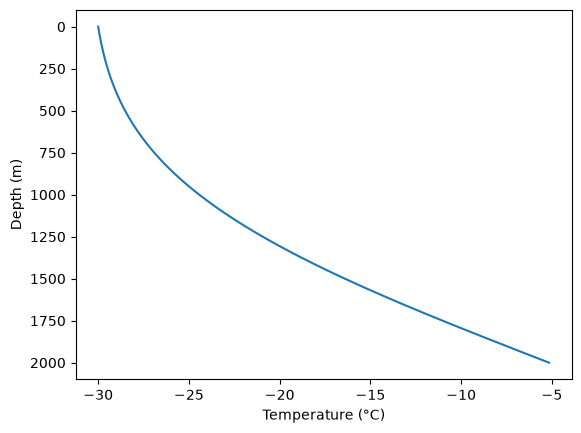

In [6]:
from src.Thermal import robin_temperature


z = np.linspace(0, 2000, 501)
T = robin_temperature(
    z, H=2000, T_surface=-30.0,
    accumulation_m_per_yr=0.10, q_b=0.050,
)

plt.plot(T, z)
plt.gca().invert_yaxis()
plt.xlabel("Temperature (°C)")
plt.ylabel("Depth (m)")
plt.show()

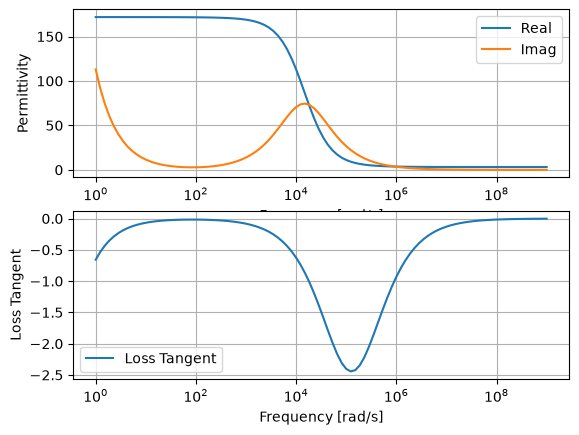

In [8]:
# Cole Cole model
from src.ConstitutiveModel import ColeColeModel, DebyeModel


# parameters are from Dawson et al 2026/2027 Fig.7
eps_s_1 = 75
eps_s_2 = 100
f1 = 5000
f2 = 500

delta_eps = [eps_s_1 - clean_ice_model.eps_infty, 
             eps_s_2 - clean_ice_model.eps_infty]

tau_0_1 = 1 / (2 * np.pi * f1)
tau_0_2 = 1 / (2 * np.pi * f2)

cc = ColeColeModel(
    eps_infty=clean_ice_model.eps_infty,
    delta_eps=delta_eps,
    sigma_s=1e-9,
    alpha=[0.05, 0.1],
    T=260
)

debye = DebyeModel(
    eps_infty=clean_ice_model.eps_infty,
    delta_eps=delta_eps,
    sigma_s=1e-9,
    tau_0=[tau_0_1, tau_0_2],
    T=260
)

omega = np.logspace(0, 9, 100) 
eps_cc  = cc.cole_cole(omega)
loss_cc = cc.loss_tangent(omega) 

plt.subplot(2,1,1)
plt.semilogx(omega, eps_cc.real)
plt.semilogx(omega, -eps_cc.imag)
plt.xlabel('Frequency [rad/s]')
plt.ylabel('Permittivity')
plt.legend(['Real', 'Imag'])
plt.grid(True)

plt.subplot(2,1,2)
plt.semilogx(omega, -loss_cc)
plt.xlabel('Frequency [rad/s]')
plt.ylabel('Loss Tangent')
plt.legend(['Loss Tangent'])
plt.grid(True)

In [36]:
from src.ConstitutiveModel import thermal_omega_ref
thermal_omega_ref(270, [1/(2*np.pi*5000), 1/(2*np.pi*500)])

np.float64(2.6490514033039755e-05)